# Step 2 · Competitive landscape of flying drones

Which applicants account for the most drone inventions, is inventive activity consolidating, who is entering, and which CPC subfields are growing? This notebook adapts sections 2, 3 and 5 of the professor’s competitive-landscape tutorial to the completed drone run. A DOCDB family is dated by its existing priority year. The applicant key is the entity ID published by the name-harmonization notebook.

On TIP, run the cells in order. Enter your existing run ID when prompted (for the completed production run, `phase2a-prod-001`). All results in this notebook are computed during execution. [Method, outputs and sharing instructions](README.md)

In [1]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
from IPython.display import display

ROOT = next(folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / "run_baseline.py").is_file())
sys.path.insert(0, str(ROOT))
from run_baseline import Run
from Step2.inputs import ATTRIBUTES, CPC, FAMILIES, FIRST_EVER, LINKS, load_first_ever, load_inputs
from Step2.competition import applicants_and_entry, concentration
from Step2.subfields import subfield_growth

if not os.environ.get("PATENT_RUN_ID"):
    os.environ["PATENT_RUN_ID"] = input("Existing PATENT_RUN_ID (for example phase2a-prod-001): ").strip()
run = Run.open(ROOT)
manifest = json.loads(run.verify("manifest.json").read_text(encoding="utf-8"))
if (manifest["env"], manifest["run_id"], manifest["config_sha256"]) != (run.env, run.run_id, run.config_sha256):
    raise ValueError("Selection manifest and run configuration differ.")
years = run.cfg["years"]
year_min, year_max = years["min"], years["max"]
last_complete = year_max - years["truncated"]
split_year, window, top_n = 2015, 3, 15
prefixes = manifest["methodology"]["cpc_prefixes"]
print(f"{run.env} / {run.run_id} | priority years {year_min}–{year_max} | complete through {last_complete}")
print("Sector CPC prefixes:", ", ".join(prefixes))

Existing PATENT_RUN_ID (for example phase2a-prod-001):  phase2a-prod-001


PROD / phase2a-prod-001 | priority years 2000–2025 | complete through 2022
Sector CPC prefixes: B64U, B64C39/024, G08G5/57


## 1. Cohort and applicant coverage

Families without an applicant stay in the extraction coverage count. The applicant metrics use families with an observed applicant link. Each joint family contributes one credit to each distinct linked entity. Multiple filings by that entity in the same family contribute a single credit. Step 0 review flags stay attached to the entities.

In [2]:
families, links, family_cpc = load_inputs(run)
linked = links["unit_id"].nunique()
coverage = pd.DataFrame([{
    "selected_families": manifest["selected_families"],
    "extracted_families": len(families),
    "families_with_applicants": linked,
    "families_without_applicants": len(families) - linked,
    "family_applicant_credits": len(links),
    "applicant_entities": links["applicant"].nunique(),
    "entities_with_review_flags": links.loc[links["needs_manual_review"], "applicant"].nunique(),
    "families_with_any_cpc": family_cpc["unit_id"].nunique(),
}])
display(coverage.T.rename(columns={0: "count"}))

,count
selected_families,168664
extracted_families,106998
families_with_applicants,106877
families_without_applicants,121
family_applicant_credits,133891
applicant_entities,42769
entities_with_review_flags,4829
families_with_any_cpc,95130


## 2. Concentration and consolidation

Shares divide each applicant’s family count by the sum of all applicant family credits. For complete years we report HHI (0–1 scale), equivalent number of applicants (1/HHI), CR4 and CR8 (%), sample coefficient of variation, Gini and the Lotka regression. These indicators measure inventive activity. Sales and market shares require separate evidence.

The tutorial specifies three-year windows. Here they start at the first configured year and do not overlap. The plot compares full three-year periods. The table also gives the final shorter period when applicable.

,period_start,period_end,years_in_period,applicants,linked_families,family_applicant_credits,cv,cr4_pct,cr8_pct,hhi,numbers_equivalent,gini,lotka_slope,lotka_pvalue
0,2000,2022,23,33953,77088,98015,5.97457,4.54624,6.71938,0.00108,925.29029,0.5961,-1.40436,0.0


,period_start,period_end,full_window,applicants,hhi,numbers_equivalent,cr4_pct
0,2000,2002,True,236,0.00646,154.79719,8.25397
1,2003,2005,True,449,0.00533,187.66335,9.47205
2,2006,2008,True,916,0.00386,259.00930,9.20535
3,2009,2011,True,1400,0.00215,465.76254,5.55556
4,2012,2014,True,2126,0.00293,341.09028,7.40288
5,2015,2017,True,8875,0.00236,424.05720,6.29975
6,2018,2020,True,13632,0.00144,692.53060,4.98463
7,2021,2022,False,12172,0.00087,1152.97098,3.62867


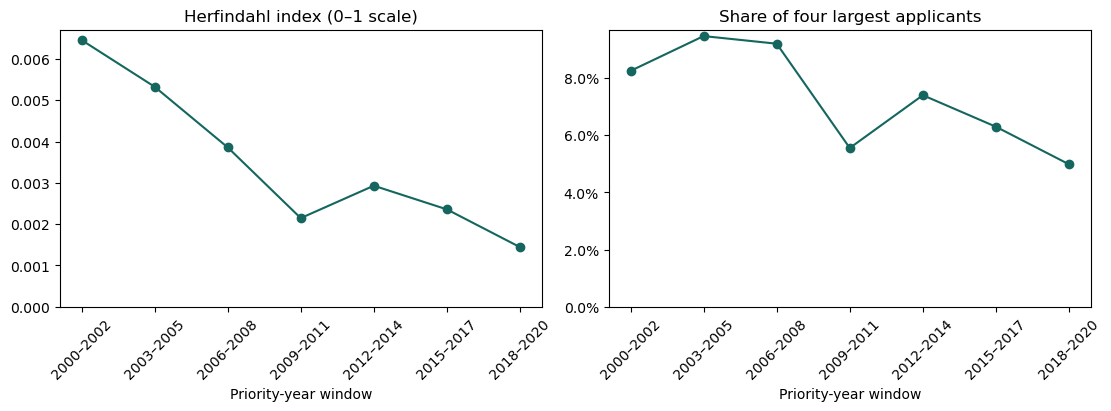

In [3]:
overall, periods = concentration(links, year_min, last_complete, window=window)
display(overall.round(5))
display(periods[["period_start", "period_end", "full_window", "applicants", "hhi", "numbers_equivalent", "cr4_pct"]].round(5))

full = periods.loc[periods["full_window"]]
fig_concentration, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
labels = [f"{a}–{b}" for a, b in zip(full["period_start"], full["period_end"])]
for ax, column, title in zip(axes, ["hhi", "cr4_pct"], ["Herfindahl index (0–1 scale)", "Share of four largest applicants"]):
    ax.plot(labels, full[column], marker="o", color="#14665f")
    ax.set(title=title, xlabel="Priority-year window", ylim=(0, None))
    ax.tick_params(axis="x", labelrotation=45)
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
plt.show()

## 3. Leading applicants and entry

The top-15 table covers the entire observed sector window, including recent incomplete years. An incumbent’s first observed drone family predates 2015. An entrant’s first observed drone family falls in 2015 or later. Founding dates or start-up status require external evidence. Use the review flag to inspect potential aliases among the leading applicants.

“New to patenting” requires a separate lookup across **all fields**. The first execution queries TIP in batches for applicant filings dated from 1900 through the configured end year. Reruns verify and reuse the saved lookup. Missing history remains visible. Each applicant’s country is the most frequent known country across distinct linked families, using alphabetical order to break ties.

In [4]:
print("Loading earliest observed filing years across all fields …", flush=True)
first_ever = load_first_ever(run, links)
ranked, annual = applicants_and_entry(links, first_ever, year_min, year_max, last_complete, split_year)
leaders = ranked.head(top_n).copy()
print(f"Known first filing year for {first_ever.notna().sum():,} of {len(first_ever):,} entities")
display(leaders)
print(f"Among these {len(leaders)} applicants, {leaders['status'].eq('incumbent').sum()} are incumbents and "
      f"{leaders['status'].eq('entrant').sum()} are sector entrants.")

Loading earliest observed filing years across all fields …
Querying first filings for PSN IDs 1–5,000 of 42,769
Querying first filings for PSN IDs 5,001–10,000 of 42,769
Querying first filings for PSN IDs 10,001–15,000 of 42,769
Querying first filings for PSN IDs 15,001–20,000 of 42,769
Querying first filings for PSN IDs 20,001–25,000 of 42,769
Querying first filings for PSN IDs 25,001–30,000 of 42,769
Querying first filings for PSN IDs 30,001–35,000 of 42,769
Querying first filings for PSN IDs 35,001–40,000 of 42,769
Querying first filings for PSN IDs 40,001–42,769 of 42,769
Known first filing year for 42,769 of 42,769 entities


,applicant,name,type,country,families,first_sector_year,last_sector_year,needs_manual_review,families_since_split,first_patent_year,status
0,PSN:31716938,SZ DJI TECHNOLOGY COMPANY,firm,CN,1964,2011,2024,True,1847,2003,incumbent
1,PSN:23153515,NANJING UNIVERSITY OF AERONAUTICS AND ASTRONAU...,university,CN,1247,2007,2024,True,1199,1987,incumbent
2,PSN:2306758,BEIHANG UNIVERSITY,university,CN,1236,2005,2024,False,1093,1985,incumbent
3,PSN:29220433,SGCC(STATE GRID CORPORATION OF CHINA),firm,CN,1210,2010,2024,False,1154,2003,incumbent
4,PSN:23854997,NORTHWESTERN POLYTECHNICAL UNIVERSITY,university,CN,1030,2007,2024,True,999,1986,incumbent
5,PSN:11095093,GUANGDONG POWER GRID CORPORATION,firm,CN,731,2013,2024,True,722,1998,incumbent
6,PSN:4929132,CHINESE ACADEMY OF SCIENCES,university,CN,729,2007,2024,False,683,1985,incumbent
7,PSN:2334217,BEIJING INSTITUTE OF TECHNOLOGY,university,CN,708,2009,2024,False,686,1988,incumbent
8,PSN:1626020,AUTEL ROBOTICS COMPANY,firm,CN,519,2015,2024,True,519,2015,entrant
9,PSN:11926380,HARBIN INSTITUTE OF TECHNOLOGY,university,CN,481,2010,2024,False,471,1985,incumbent


Among these 15 applicants, 13 are incumbents and 2 are sector entrants.


A family with multiple sector entrants counts once in the entrants’ share. Its denominator includes the year’s distinct families with applicant links. The disappearance rate uses an applicant’s last **observed** sector family and is reported only through three years before the last complete year. The beginning of the window can make established applicants look new to the sector. Shading marks incomplete recent years.

,year,active_applicants,new_to_sector,new_to_patenting,last_observed,linked_families,families_with_entrant,unknown_first_patent_year,entrant_family_share_pct,disappearance_pct,incomplete_year
0,2000,85,85,34,60,63,63,0,100.00,70.59,False
1,2001,82,74,35,52,69,55,0,79.71,63.41,False
2,2002,87,77,36,51,68,53,0,77.94,58.62,False
3,2003,159,148,85,105,109,81,0,74.31,66.04,False
4,2004,144,120,62,92,77,60,0,77.92,63.89,False
5,2005,187,158,91,128,118,86,0,72.88,68.45,False
6,2006,305,254,136,229,155,121,0,78.06,75.08,False
7,2007,262,219,124,194,160,122,0,76.25,74.05,False
8,2008,419,362,224,313,221,163,0,73.76,74.70,False
9,2009,467,377,195,325,253,188,0,74.31,69.59,False


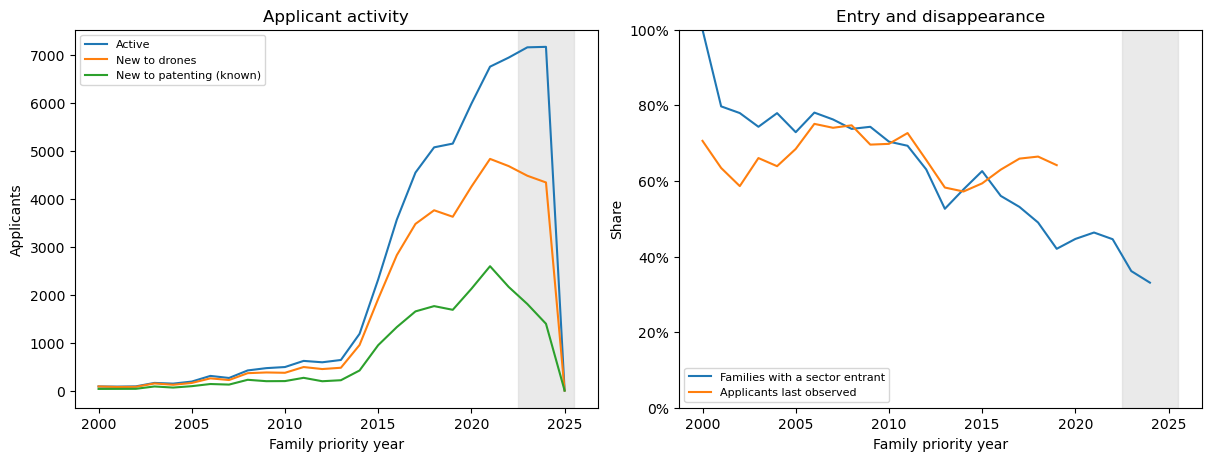

In [5]:
display(annual.round(2))
fig_entry, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for key, label in [("active_applicants", "Active"), ("new_to_sector", "New to drones"), ("new_to_patenting", "New to patenting (known)")]:
    axes[0].plot(annual["year"], annual[key].to_numpy(dtype=float, na_value=float("nan")), label=label)
for key, label in [("entrant_family_share_pct", "Families with a sector entrant"), ("disappearance_pct", "Applicants last observed")]:
    axes[1].plot(annual["year"], annual[key], label=label)
axes[0].set(ylabel="Applicants", title="Applicant activity")
axes[1].set(ylabel="Share", title="Entry and disappearance", ylim=(0, 100))
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
for ax in axes:
    ax.axvspan(last_complete + 0.5, year_max + 0.5, color="0.8", alpha=0.4)
    ax.set_xlabel("Family priority year")
    ax.legend(fontsize=8)
plt.show()

## 4. Growing CPC subfields

Match the sealed sector CPC prefixes, then group matching symbols by their first two digits after the slash. One family can belong to several subfields. Compare two successive five-year windows ending in the last complete year. A new group with zero families in the earlier window receives a blank growth rate. The three labels on the chart follow the tutorial’s median recent-size screen among groups with a positive baseline. Read small baselines alongside percentage growth.

Earlier period 2013–2017; recent period 2018–2022


,past_families,recent_families,growth_pct
subfield,,,
B64C39/02,1321,4503,240.88
B64U2101/30,3070,3858,25.67
B64U2101/00,1278,3637,184.59
B64U10/10,1705,3462,103.05
B64U50/19,1874,3223,71.99
...,...,...,...
B64U50/16,7,10,42.86
B64U50/36,10,10,0.00
B64U80/50,19,8,-57.89


Fastest growth among eligible subfields


,past_families,recent_families,growth_pct
subfield,,,
B64U2101/18,23,83,260.87
B64C39/02,1321,4503,240.88
B64U2101/25,48,159,231.25


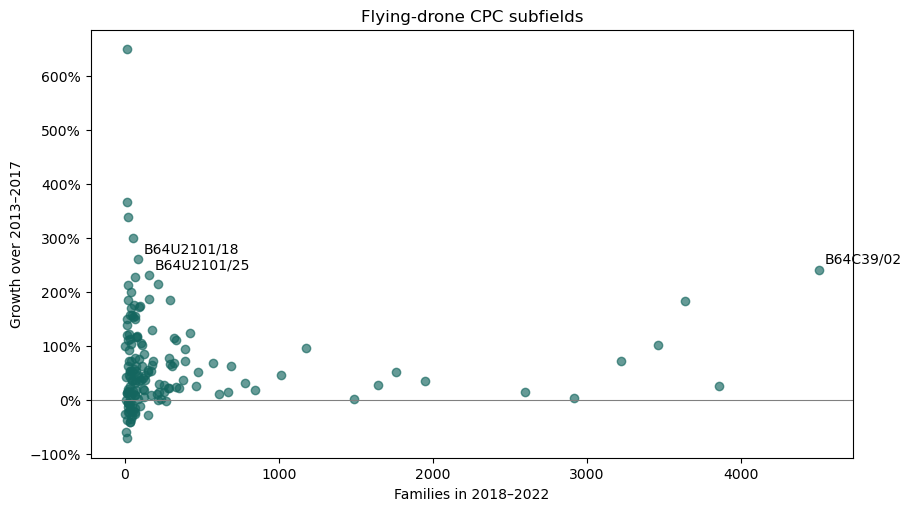

In [6]:
subfields, fastest = subfield_growth(family_cpc, prefixes, last_complete)
past_label = f"{last_complete - 9}–{last_complete - 5}"
recent_label = f"{last_complete - 4}–{last_complete}"
print(f"Earlier period {past_label}; recent period {recent_label}")
display(subfields.round(2))
print("Fastest growth among eligible subfields")
display(fastest.round(2))

comparable = subfields.dropna(subset=["growth_pct"])
fig_cpc, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.scatter(comparable["recent_families"], comparable["growth_pct"], color="#14665f", alpha=0.65)
for name, row in fastest.iterrows():
    ax.annotate(name, (row["recent_families"], row["growth_pct"]), xytext=(4, 5), textcoords="offset points")
ax.axhline(0, color="0.5", linewidth=0.8)
ax.set(xlabel=f"Families in {recent_label}", ylabel=f"Growth over {past_label}", title="Flying-drone CPC subfields")
ax.yaxis.set_major_formatter(PercentFormatter(100))
plt.show()

## 5. PEST evidence

This evidence table concerns the European civil-drone market. Read each finding in its stated geography and period. The implications are interpretations for discussion. Open the named sources before quoting them in the deck.

In [7]:
from hashlib import sha256
from io import BytesIO

pest_bytes = (ROOT / "Step2" / "pest.csv").read_bytes()
pest = pd.read_csv(BytesIO(pest_bytes))
with pd.option_context("display.max_colwidth", None):
    display(pest)

,factor,scope,evidence,competitive_implication,source,year,url
0,Political,"European Union, civil drone operations","Article 3 distinguishes three categories of UAS operations (open, specific and certified). The category governs which conditions an operator must meet.","For a prospective operator, the approval effort depends on the intended service. When comparing entrants, check which operations each has obtained permission to offer.","European Commission, Implementing Regulation (EU) 2019/947, Articles 3–6",2019,https://eur-lex.europa.eu/eli/reg_impl/2019/947/oj/eng
1,Economic,"European Union, drone services, 2030 scenario",Drone Strategy 2.0 reports a projection that the European drone services market could reach EUR 14.5 billion by 2030. The figure is a forecast issued in 2022.,Growth in services could create demand for operators and their suppliers. Use realised service revenues or contract awards to assess individual competitors.,"European Commission, A Drone Strategy 2.0 for a Smart and Sustainable Unmanned Aircraft Eco-System in Europe, COM(2022) 652 final",2022,https://eur-lex.europa.eu/legal-content/EN/TXT/?uri=CELEX:52022DC0652
2,Social,"Selected European urban areas, surveyed residents, urban air mobility",The EASA survey found support for medical and emergency uses and identified concerns including safety and noise. The study covered both drones and passenger air taxis.,Public acceptance may differ by mission. Compare medical delivery and routine parcel delivery separately when evaluating prospects for urban drone services.,"European Union Aviation Safety Agency, Study on the societal acceptance of Urban Air Mobility in Europe",2021,https://www.easa.europa.eu/en/document-library/general-publications/study-societal-acceptance-urban-air-mobility-europe
3,Technological,"European Union, designated U-space airspace","The U-space framework specifies four mandatory services in designated airspace. They cover network identification, geo-awareness, UAS flight authorisation and traffic information.",Compatibility with these services can matter to operators and create opportunities for software and integration suppliers. Verify implementation in each target area.,"European Commission, Implementing Regulation (EU) 2021/664, Article 3",2021,https://eur-lex.europa.eu/eli/reg_impl/2021/664/oj/eng


## 6. Publish the Step 2 tables and figures

The run publisher records input fingerprints and protects existing artifacts. The full applicant ranking stays in a CSV on TIP. The top 15, annual series, growth map and PEST table appear directly in the saved notebook for your teammates.

In [8]:
app_inputs = (FAMILIES, LINKS, ATTRIBUTES)
growth_inputs = ("manifest.json", FAMILIES, CPC)
entry_inputs = (*app_inputs, FIRST_EVER)
settings = {"split_year": split_year, "window_years": window, "last_complete_year": last_complete}
growth_settings = {"prefixes": prefixes, "past_period": past_label, "recent_period": recent_label}

def publish_table(name, frame, inputs, metadata=None):
    path = run.publish(f"step2/{name}.csv", lambda out: frame.to_csv(out, index=False),
                       inputs=inputs, metadata=metadata)
    print(path.name, flush=True)

publish_table("coverage", coverage, ("manifest.json", *app_inputs, CPC))
publish_table("concentration", overall, app_inputs, settings)
publish_table("concentration_windows", periods, app_inputs, settings)
publish_table("applicant_ranking", ranked, entry_inputs, settings)
publish_table("top_applicants", leaders, ("step2/applicant_ranking.csv",), {"top_n": top_n})
publish_table("entry_exit", annual, entry_inputs, settings)
publish_table("cpc_subfields", subfields.reset_index(), growth_inputs, growth_settings)
publish_table("fastest_subfields", fastest.reset_index(), ("step2/cpc_subfields.csv",))
publish_table("pest", pest, (), {"source_file": "Step2/pest.csv", "sha256": sha256(pest_bytes).hexdigest()})

for name, figure, table in [
    ("concentration_trend", fig_concentration, "concentration_windows"),
    ("entry_exit", fig_entry, "entry_exit"),
    ("subfield_growth", fig_cpc, "cpc_subfields"),
]:
    run.publish(f"step2/{name}.png", lambda out: figure.savefig(out, dpi=150, format="png"),
                inputs=(f"step2/{table}.csv",))
print("Saved Step 2 outputs in", run.directory / "step2")

coverage.csv
concentration.csv
concentration_windows.csv
applicant_ranking.csv
top_applicants.csv
entry_exit.csv
cpc_subfields.csv
fastest_subfields.csv
pest.csv
Saved Step 2 outputs in /home/jovyan/flying-drones-phase2a/outputs/runs/PROD/phase2a-prod-001/step2


The competitive-landscape tutorial is by Grazia Sveva Ascione, Politecnico di Torino, drawing on original European Patent Office training material. This course-project adaptation is for non-commercial teaching and learning. The EPO has not authorised the adaptation and accepts no responsibility for its correctness. [Professor’s Step 2 notebook](https://github.com/Soroushkhayami/innovation-management-datascience26/blob/f1bca0b6ab2310d174cd9588c13f144b0e6492f1/tutorial_1/11_competitive_landscape.ipynb) · [Course terms](https://github.com/Soroushkhayami/innovation-management-datascience26/blob/f1bca0b6ab2310d174cd9588c13f144b0e6492f1/LICENSE.md)